# IBM Quantum Nighthawk を量子シミュレータ上で再現する

このノートブックでは、IBMの正方格子プロセッサー **Nighthawk** を手元のシミュレータで再現し、ヘビーヘックス格子の **Heron** と比べます。

| 章 | 内容 |
|---|---|
| 1 | 環境の準備 |
| 2 | フェイクバックエンド `FakeMiami`（Nighthawk r1 の実機スナップショット）を読み込む |
| 3 | 格子を図にする（正方格子 vs ヘビーヘックス） |
| 4 | ノイズモデルの中身を見る |
| 5 | ノイズ付きシミュレーション（GHZ状態） |
| 6 | Nighthawk型バックエンドを**自作**する（誤り率を自由に変えられる） |
| 7 | Heron（`FakeBoston`）との比較：同じ回路のCZ数・深さ・成功確率 |
| 8 | 量子化学：LUCJ回路で格子の違いがどう効くか（＋SQDでエネルギー計算） |
| 9 | **Nighthawk r2（ibm_phoenix）を再現**し、7・8章の比較をやり直す |
| 10 | まとめと次のステップ |

**前提**

- フェイクバックエンドの誤り率や T1/T2 は、**ある時点の実機の値を写したもの**です。今日の実機の値とは違います。
- ibm_phoenix（Nighthawk r2）のフェイク版は、まだ提供されていません。9章で、公開値をもとに r2 を自分で組み立てます。
- 全セルの実行時間は、ノートPCで 10〜15 分ほどです。一番重いのは 8.2 節と 9.3 節のノイズ付きサンプリングです。

## 1. 環境の準備

必要なライブラリは次のとおりです。

- `qiskit`：回路の作成とトランスパイル
- `qiskit-ibm-runtime`（**0.47以上**）：`FakeMiami` などのフェイクバックエンドが入っています
- `qiskit-aer`：ノイズ付きシミュレータ
- `ffsim`, `pyscf`, `qiskit-addon-sqd`：量子化学（8章）で使います

初めて実行するときは、次のセルのコメント（`#`）を外してインストールしてください。

In [1]:
%pip install -U "qiskit>=2.0" "qiskit-ibm-runtime>=0.47" qiskit-aer ffsim pyscf qiskit-addon-sqd matplotlib pandas networkx

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import collections, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, QuantumRegister, transpile
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime import SamplerV2
from qiskit_ibm_runtime.fake_provider import FakeMiami, FakeBoston

print("qiskit            ", qiskit.__version__)
print("qiskit-aer        ", qiskit_aer.__version__)
print("qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

qiskit             2.6.0
qiskit-aer         0.17.2
qiskit-ibm-runtime 0.50.0


## 2. Nighthawk のフェイクバックエンドを読み込む

`qiskit-ibm-runtime` には Nighthawk 系のフェイクバックエンドが3つあります。

| クラス | 中身 |
|---|---|
| `FakeMiami` | 実機 **ibm_miami**（Nighthawk r1）の配線と誤り率のスナップショット ← **このノートで主に使う** |
| `FakeBerlin` | 実機 ibm_berlin（Nighthawk r1）のスナップショット |
| `FakeNighthawk` | 汎用モデル。誤り率は「典型的な値を表すものではない」と公式に注意書きがあるので、性能評価には向きません |

比較相手として、論文（arXiv:2607.25941）で使われた **ibm_boston（Heron r3）** の `FakeBoston` も読み込みます。

下の `summarize()` 関数は、バックエンドの `target`（どのゲートをどの量子ビットで実行でき、誤り率はいくつか、という情報の表）から、主な数値を取り出します。

In [3]:
miami  = FakeMiami()    # Nighthawk r1（正方格子）
boston = FakeBoston()   # Heron r3（ヘビーヘックス）

def undirected_graph(backend):
    # カップリングマップは (a,b) と (b,a) の両方向で入っているので、無向グラフにまとめる
    g = nx.Graph()
    g.add_nodes_from(range(backend.num_qubits))
    g.add_edges_from(backend.coupling_map.get_edges())
    return g

def median_error(backend, gate):
    t = backend.target
    errs = [p.error for p in t[gate].values() if p is not None and p.error is not None]
    return float(np.median(errs))

def summarize(backend):
    g = undirected_graph(backend)
    deg = collections.Counter(d for _, d in g.degree())
    t1 = [backend.qubit_properties(q).t1 for q in range(backend.num_qubits)]
    t2 = [backend.qubit_properties(q).t2 for q in range(backend.num_qubits)]
    return {
        "量子ビット数": backend.num_qubits,
        "カプラー数（結合の本数）": g.number_of_edges(),
        "次数の分布 {結合数: 個数}": dict(sorted(deg.items())),
        "ネイティブゲート": sorted(set(backend.operation_names) & {"cz", "sx", "x", "rz", "id"}),
        "CZ誤り率（中央値）": median_error(backend, "cz"),
        "SX誤り率（中央値）": median_error(backend, "sx"),
        "読み出し誤り率（中央値）": median_error(backend, "measure"),
        "T1 中央値 [µs]": np.median(t1) * 1e6,
        "T2 中央値 [µs]": np.median(t2) * 1e6,
    }

summary = pd.DataFrame({"FakeMiami (Nighthawk r1)": summarize(miami),
                        "FakeBoston (Heron r3)":   summarize(boston)})
summary

,FakeMiami (Nighthawk r1),FakeBoston (Heron r3)
量子ビット数,120,156
カプラー数（結合の本数）,218,176
次数の分布 {結合数: 個数},"{2: 4, 3: 36, 4: 80}","{1: 8, 2: 100, 3: 48}"
ネイティブゲート,"[cz, id, rz, sx, x]","[cz, id, rz, sx, x]"
CZ誤り率（中央値）,0.002978,0.001275
SX誤り率（中央値）,0.000197,0.000145
読み出し誤り率（中央値）,0.017883,0.005127
T1 中央値 [µs],330.217672,292.435651
T2 中央値 [µs],241.90914,352.9696


**表の読み方**

- **カプラー数：** Miami は 120 量子ビットで 218 本、Boston は 156 量子ビットで 176 本です。量子ビットの数は Miami のほうが少ないのに、結合は Miami のほうが多くなっています。
- **次数の分布：** Miami はほとんどの量子ビットが **4本**（上下左右）とつながっています。Boston は **2本か3本**です。これがそれぞれ、正方格子とヘビーヘックスの特徴です。
- **CZ誤り率・読み出し誤り率：** このスナップショットでは、**Boston のほうが誤り率が低い**です（CZ で約 2.3 倍、読み出しで約 3.5 倍の差）。「Nighthawk は回路が浅くなるが、1ゲートの質ではまだ Heron r3 が上」という**トレードオフ**が、7〜8章で効いてきます。
- **T1：** Miami のほうが長めです。IBMは ibm_miami の発表時に「T1 中央値 350 µs で、保有機の中で最長」と案内していました。

## 3. 格子を図にする

Qiskit の `plot_gate_map` は、量子ビットの座標を知らない機体では自動配置（ばねモデル）で描くので、格子がゆがんで見えます。そこで、**実際の格子どおりの座標**を自分で与えて描きます。

- **Miami：** 12行×10列の格子です。量子ビット番号 `q` は `(行, 列) = (q // 10, q % 10)` に対応します。
- **Boston：** 16量子ビットの横一列が8段あります。段と段の間を、4つずつの「橋渡し」量子ビットがつないでいます。橋渡しの位置は、段ごとに列 3,7,11,15 と 列 1,5,9,13 が交互に入れ替わります。

下のコードでは、この座標が本当に正しいかを `assert`（座標上で隣同士の量子ビットだけが結合していることの確認）で検証してから描画しています。

In [4]:
def coords_nighthawk(q, ncols=10):
    return (q // ncols, q % ncols)

def coords_heron(q):
    block, k = divmod(q, 20)          # 1ブロック = 横一列16個 + 橋渡し4個
    if k < 16:
        return (2 * block, k)
    cols = [3, 7, 11, 15] if block % 2 == 0 else [1, 5, 9, 13]
    return (2 * block + 1, cols[k - 16])

def check_coords(backend, f):
    for a, b in backend.coupling_map.get_edges():
        (ra, ca), (rb, cb) = f(a), f(b)
        assert abs(ra - rb) + abs(ca - cb) == 1, (a, b)
    return True

print("Miami  の座標OK:", check_coords(miami, coords_nighthawk))
print("Boston の座標OK:", check_coords(boston, coords_heron))

Miami  の座標OK: True
Boston の座標OK: True


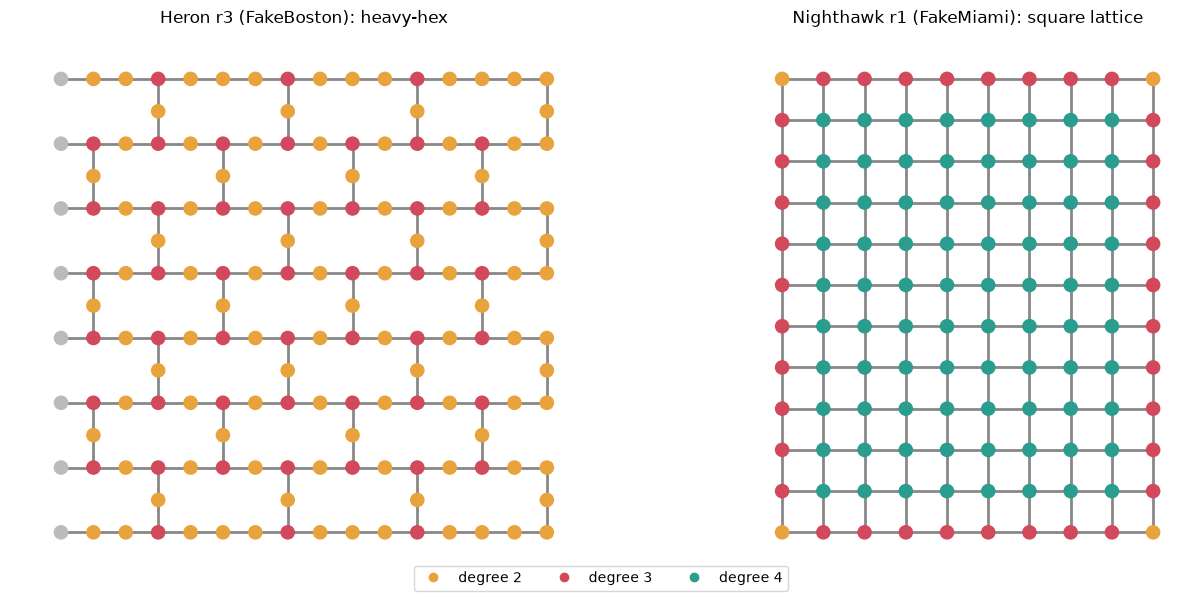

In [6]:
def draw_lattice(backend, coord_fn, ax, title, node_color=None, edge_color=None,
                 cmap="viridis", node_size=90, label=None):
    g = undirected_graph(backend)
    pos = {q: (coord_fn(q)[1], -coord_fn(q)[0]) for q in g.nodes}
    ec = [edge_color[tuple(sorted(e))] for e in g.edges] if edge_color else "#888888"
    ed = nx.draw_networkx_edges(g, pos, ax=ax, edge_color=ec, width=2.0,
                                edge_cmap=plt.get_cmap(cmap) if edge_color else None)
    nc = [node_color[q] for q in g.nodes] if node_color else "#4C72B0"
    nd = nx.draw_networkx_nodes(g, pos, ax=ax, node_color=nc, node_size=node_size,
                                cmap=plt.get_cmap(cmap) if node_color else None)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
    return nd, ed

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, be, f, name in [(axes[0], boston, coords_heron, "Heron r3 (FakeBoston): heavy-hex"),
                        (axes[1], miami, coords_nighthawk, "Nighthawk r1 (FakeMiami): square lattice")]:
    deg = dict(undirected_graph(be).degree())
    colors = {q: {1: "#BBBBBB", 2: "#E8A33D", 3: "#D1495B", 4: "#2A9D8F"}[deg[q]] for q in deg}
    draw_lattice(be, f, ax, name, node_color=colors)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=f"degree {d}")
           for d, c in [(2, "#E8A33D"), (3, "#D1495B"), (4, "#2A9D8F")]]
fig.legend(handles=handles, loc="lower center", ncol=3)
plt.tight_layout(); plt.show()

色は「その量子ビットが何本の結合を持つか（次数）」を表しています。

- 左（Heron）は、オレンジ（2本）と赤（3本）だけです。
- 右（Nighthawk）は、内側がほぼすべて緑（4本）です。

次に、同じ図を使って **CZゲートの誤り率**（線の色）と**読み出し誤り率**（点の色）を描きます。実機ではカプラーごとに品質がばらつくので、「どの量子ビットを使うか」で結果が変わります。トランスパイラはこの情報を使って、誤りの少ない場所に回路を配置します。

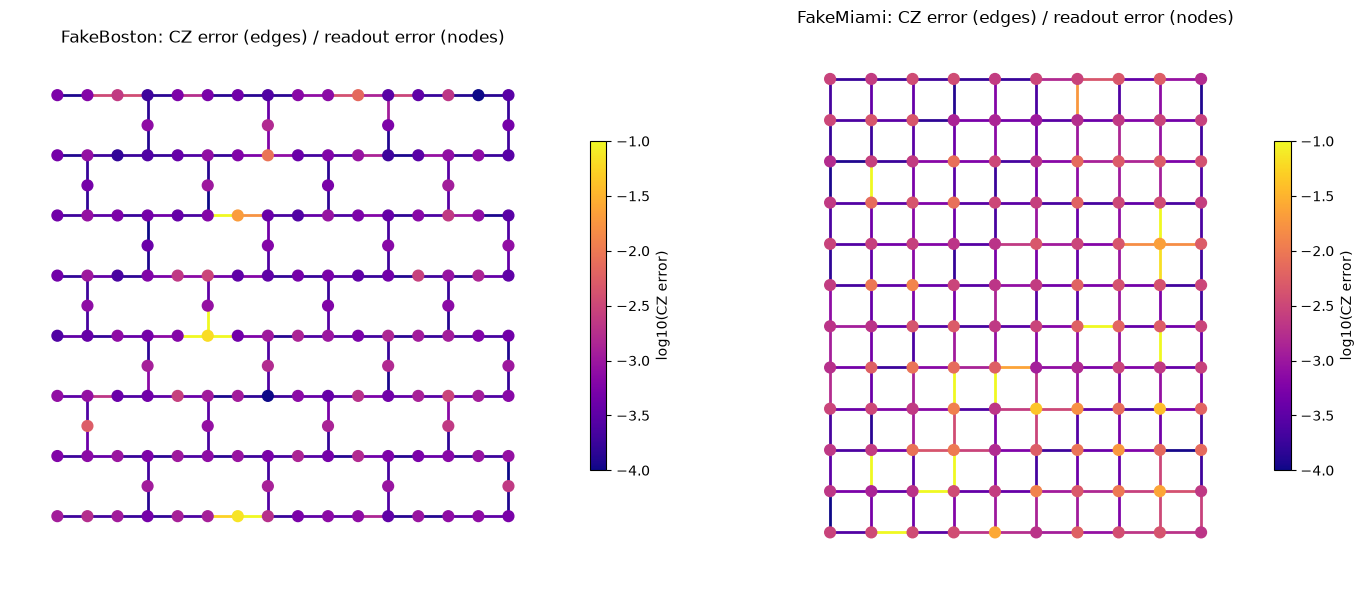

In [7]:
def edge_errors(backend):
    out = {}
    for (a, b), p in backend.target["cz"].items():
        if p is not None and p.error is not None:
            key = tuple(sorted((a, b)))
            out[key] = max(out.get(key, 0), p.error)
    return out

def readout_errors(backend):
    return {q[0]: p.error for q, p in backend.target["measure"].items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, be, f, name in [(axes[0], boston, coords_heron, "FakeBoston"),
                        (axes[1], miami, coords_nighthawk, "FakeMiami")]:
    ee = edge_errors(be); ee_log = {k: np.log10(min(max(v, 1e-4), 1e-1)) for k, v in ee.items()}
    ro = readout_errors(be); ro_log = {k: np.log10(min(max(v, 1e-3), 0.3)) for k, v in ro.items()}
    nd, ed = draw_lattice(be, f, ax, name + ": CZ error (edges) / readout error (nodes)",
                          node_color=ro_log, edge_color=ee_log, cmap="plasma", node_size=60)
    ed.set_clim(-4, -1); nd.set_clim(-3, np.log10(0.3))
    fig.colorbar(ed, ax=ax, shrink=0.6, label="log10(CZ error)")
plt.tight_layout(); plt.show()

## 4. ノイズモデルの中身

`AerSimulator.from_backend(backend)` を使うと、Qiskit Aer が `target` の情報から**ノイズモデル**を自動で作ります。中身は主に次の3つです。

1. **ゲート誤り：** 各ゲートの後に、誤り率に合わせた脱分極ノイズを入れます。
2. **熱緩和（T1/T2）：** ゲートの実行時間に応じて、エネルギー緩和と位相緩和を入れます。
3. **読み出し誤り：** 測定結果の 0 と 1 が、ある確率で入れ替わります。

下では、量子ビットごとのばらつきをヒストグラムで比べます。

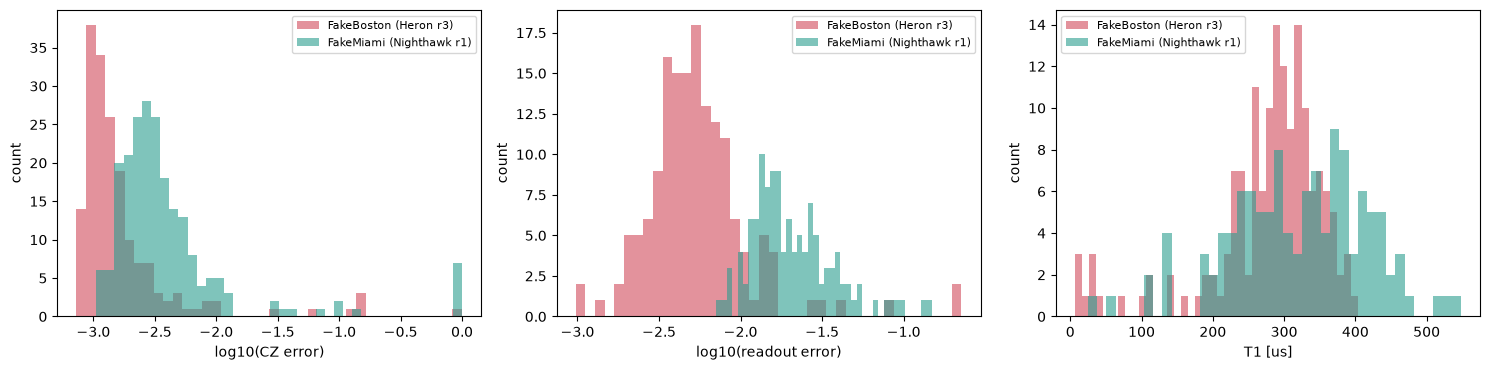

ノイズが入る命令: ['cz', 'id', 'measure', 'sx', 'x']


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for be, name, c in [(boston, "FakeBoston (Heron r3)", "#D1495B"), (miami, "FakeMiami (Nighthawk r1)", "#2A9D8F")]:
    cz = list(edge_errors(be).values())
    axes[0].hist(np.log10(cz), bins=40, alpha=0.6, label=name, color=c)
    ro = list(readout_errors(be).values())
    axes[1].hist(np.log10(ro), bins=40, alpha=0.6, label=name, color=c)
    t1 = [be.qubit_properties(q).t1 * 1e6 for q in range(be.num_qubits)]
    axes[2].hist(t1, bins=40, alpha=0.6, label=name, color=c)
axes[0].set_xlabel("log10(CZ error)"); axes[1].set_xlabel("log10(readout error)"); axes[2].set_xlabel("T1 [us]")
for ax in axes: ax.set_ylabel("count"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

nm = NoiseModel.from_backend(miami)
print("ノイズが入る命令:", nm.noise_instructions)

## 5. ノイズ付きシミュレーション：GHZ状態

まずは簡単な例です。$n$ 量子ビットの GHZ 状態 $(|00\cdots0\rangle + |11\cdots1\rangle)/\sqrt2$ を作って測定します。理想的には `00…0` と `11…1` だけが半々で出ます。ここでは、この2つが出る確率の合計を **GHZ成功率** と呼んで、ノイズの強さの目安にします。

実行の流れは、実機で使うときとまったく同じです。

1. 回路を作る
2. **トランスパイル**：バックエンドのネイティブゲート（CZ, SX, RZ…）と格子に合わせて書き換えます。`optimization_level=3` を指定すると、誤りの少ない量子ビットを選んで配置してくれます。
3. `SamplerV2(mode=AerSimulator.from_backend(...))` で実行します。実機なら `mode` に本物のバックエンドを渡すだけです。

> Aer は、回路で使われていない量子ビットを自動で省いてシミュレーションします。そのため、120 量子ビットの機体でも、実際に計算するのは使った量子ビットの分だけです。

In [9]:
def ghz(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    qc.measure_all()
    return qc

def ghz_success(counts, n):
    shots = sum(counts.values())
    return (counts.get("0" * n, 0) + counts.get("1" * n, 0)) / shots

def run_counts(isa_circuit, backend, shots=2000, seed=7):
    sim = AerSimulator.from_backend(backend, seed_simulator=seed)
    res = SamplerV2(mode=sim).run([isa_circuit], shots=shots).result()
    return res[0].data.meas.get_counts()

rows = []
for n in [4, 8, 12, 16]:
    for name, be in [("FakeBoston (Heron r3)", boston), ("FakeMiami (Nighthawk r1)", miami)]:
        isa = transpile(ghz(n), be, optimization_level=3, seed_transpiler=1)
        p = ghz_success(run_counts(isa, be), n)
        rows.append({"n": n, "backend": name, "CZ数": isa.count_ops().get("cz", 0), "GHZ成功率": p})
ghz_df = pd.DataFrame(rows)
ghz_df.pivot(index="n", columns="backend", values="GHZ成功率").round(3)

backend,FakeBoston (Heron r3),FakeMiami (Nighthawk r1)
n,,
4,0.988,0.958
8,0.962,0.890
12,0.948,0.846
16,0.923,0.774


GHZ 回路は「一直線の鎖」でできているので、ヘビーヘックスにも正方格子にも、SWAPなしでそのまま載ります（CZ数は両方とも $n-1$ 個）。つまりこの比較では、**格子の差ではなく、1ゲートあたりの誤り率の差だけ**が結果に出ています。

格子の差が出るのは、**鎖に収まらない回路**（2次元的な相互作用や、遠い量子ビット同士の相互作用を含む回路）です。それを 7〜8 章で見ます。

## 6. Nighthawk型バックエンドを自作する

フェイクバックエンドは便利ですが、誤り率は固定です。研究では、次のようなことを確かめたくなります。

- 「格子の形だけ」の効果を見たい（誤り率を Heron とそろえたら、正方格子はどれだけ有利か）
- 将来の r2/r3 を想定して、誤り率を半分にしたらどうなるか

そこで、**正方格子＋自由に決められる誤り率**のバックエンドを自作します。Qiskit では、`Target`（命令と誤り率の表）を自分で組み立てて `BackendV2` に包めば、フェイクバックエンドとまったく同じように使えます。トランスパイルも `AerSimulator.from_backend` も、そのまま動きます。

`make_nighthawk_like()` の引数は次のとおりです。

| 引数 | 意味 | 既定値 |
|---|---|---|
| `rows, cols` | 格子の大きさ | 12×10（＝120量子ビット、Nighthawk と同じ） |
| `cz_error, sq_error, readout_error` | 2量子ビット／1量子ビット／読み出しの誤り率 | `FakeMiami` の中央値 |
| `t1, t2` | コヒーレンス時間 [秒] | `FakeMiami` の中央値 |
| `cz_duration` など | ゲートの時間 [秒] | `FakeMiami` の中央値 |

すべての量子ビットとカプラーに**同じ値**を入れるので、実機のような「場所によるばらつき」はありません。格子の効果だけを切り出したいときには、むしろこのほうが好都合です。

In [9]:
from qiskit.transpiler import Target, InstructionProperties
from qiskit.circuit import Parameter, Measure, Delay
from qiskit.circuit.library import CZGate, SXGate, XGate, RZGate, IGate
from qiskit.providers import BackendV2, Options, QubitProperties


class NighthawkLike(BackendV2):
    # Target を持つだけの最小限のバックエンド。run() は Aer に任せる
    def __init__(self, target, name="nighthawk_like"):
        super().__init__(name=name)
        self._target = target

    @property
    def target(self):
        return self._target

    @property
    def max_circuits(self):
        return None

    @classmethod
    def _default_options(cls):
        return Options(shots=1024)

    def run(self, run_input, **options):
        return AerSimulator.from_backend(self).run(run_input, **options)


def _median_duration(backend, gate):
    return float(np.median([p.duration for p in backend.target[gate].values()
                            if p is not None and p.duration is not None]))

REF = miami   # 既定値を取ってくる元
DEFAULTS = dict(
    cz_error=median_error(REF, "cz"),
    sq_error=median_error(REF, "sx"),
    readout_error=median_error(REF, "measure"),
    t1=float(np.median([REF.qubit_properties(q).t1 for q in range(REF.num_qubits)])),
    t2=float(np.median([REF.qubit_properties(q).t2 for q in range(REF.num_qubits)])),
    cz_duration=_median_duration(REF, "cz"),
    sq_duration=_median_duration(REF, "sx"),
    meas_duration=_median_duration(REF, "measure"),
)

def make_nighthawk_like(rows=12, cols=10, name="nighthawk_like", **overrides):
    p = {**DEFAULTS, **overrides}
    n = rows * cols
    cmap = CouplingMap.from_grid(rows, cols)          # 量子ビット q = 行*cols + 列（FakeMiami と同じ番号づけ）
    qprops = [QubitProperties(t1=p["t1"], t2=min(p["t2"], 2 * p["t1"]), frequency=5e9) for _ in range(n)]
    target = Target(num_qubits=n, dt=REF.target.dt, qubit_properties=qprops)
    target.add_instruction(CZGate(), {e: InstructionProperties(p["cz_duration"], p["cz_error"])
                                      for e in cmap.get_edges()})
    for gate in (SXGate(), XGate(), IGate()):
        target.add_instruction(gate, {(q,): InstructionProperties(p["sq_duration"], p["sq_error"]) for q in range(n)})
    target.add_instruction(RZGate(Parameter("θ")), {(q,): InstructionProperties(0.0, 0.0) for q in range(n)})  # 仮想Zなので誤り0
    target.add_instruction(Measure(), {(q,): InstructionProperties(p["meas_duration"], p["readout_error"]) for q in range(n)})
    target.add_instruction(Delay(Parameter("t")), {(q,): None for q in range(n)})
    return NighthawkLike(target, name=name)

pd.Series(DEFAULTS, name="FakeMiami から取った既定値")

cz_error         2.978229e-03
sq_error         1.971268e-04
readout_error    1.788330e-02
t1               3.302177e-04
t2               2.419091e-04
cz_duration      1.380000e-07
sq_duration      3.200000e-08
meas_duration    2.400000e-06
Name: FakeMiami から取った既定値, dtype: float64

では、2種類の自作バックエンドを作ります。

- `nh_miami_err`：正方格子＋**Miami 並み**の誤り率（Miami の「ばらつきなし版」）
- `nh_heron_err`：正方格子＋**Boston（Heron r3）並み**の誤り率 → 「もし Nighthawk が Heron r3 と同じ品質だったら」

作ったら、GHZ を流して `FakeMiami` と同じような振る舞いになるかを確認します。

In [10]:
heron_err = dict(
    cz_error=median_error(boston, "cz"),
    sq_error=median_error(boston, "sx"),
    readout_error=median_error(boston, "measure"),
    t1=float(np.median([boston.qubit_properties(q).t1 for q in range(boston.num_qubits)])),
    t2=float(np.median([boston.qubit_properties(q).t2 for q in range(boston.num_qubits)])),
)
nh_miami_err = make_nighthawk_like(name="nighthawk_like (Miami errors)")
nh_heron_err = make_nighthawk_like(name="nighthawk_like (Heron r3 errors)", **heron_err)

print(nh_miami_err.name, nh_miami_err.num_qubits, "qubits,",
      undirected_graph(nh_miami_err).number_of_edges(), "couplers")

rows = []
for n in [4, 8, 12, 16]:
    for be in [nh_miami_err, nh_heron_err]:
        isa = transpile(ghz(n), be, optimization_level=3, seed_transpiler=1)
        rows.append({"n": n, "backend": be.name, "GHZ成功率": ghz_success(run_counts(isa, be), n)})
pd.concat([ghz_df[["n", "backend", "GHZ成功率"]], pd.DataFrame(rows)]) \
  .pivot(index="n", columns="backend", values="GHZ成功率").round(3)

nighthawk_like (Miami errors) 120 qubits, 218 couplers


backend,FakeBoston (Heron r3),FakeMiami (Nighthawk r1),nighthawk_like (Heron r3 errors),nighthawk_like (Miami errors)
n,,,,
4,0.988,0.958,0.980,0.924
8,0.962,0.890,0.948,0.839
12,0.948,0.848,0.928,0.781
16,0.923,0.774,0.894,0.694


自作の `nighthawk_like (Miami errors)` は、`FakeMiami` と近い値になるはずです。`FakeMiami` のほうが少し良くなることがありますが、これはトランスパイラが**特に誤りの少ない量子ビットを選べる**からです。ばらつきのない自作版には、その「当たりの量子ビット」がありません。

これで、正方格子の機体をシミュレータ上で再現する道具がそろいました。

## 7. Heron との比較：格子の違いが効く回路

次の4種類のベンチマーク回路を、各バックエンド向けにトランスパイルして比べます。

| 回路 | 構造 | 予想 |
|---|---|---|
| 1D Ising（20量子ビット・鎖） | 隣同士だけ | 差は出ない（どちらにも鎖は載る） |
| 2D Ising（4×5格子） | 上下左右の隣 | **正方格子が有利**（そのまま載る） |
| QAOA（20頂点のランダム3正則グラフ） | ばらばらの相手 | 正方格子がやや有利（SWAPが減る） |
| QFT（12量子ビット） | 全員と全員 | 正方格子がやや有利 |

比べる指標は次の3つです。

- **CZ数：** 2量子ビットゲートの総数。SWAP が増えるとここが増えます。
- **2量子ビット深さ：** 2量子ビットゲートの層の数。実行時間（デコヒーレンス）に効きます。
- **ESP（Estimated Success Probability）：** 回路中のすべての命令について (1 − 誤り率) を掛け合わせた値。「誤りが一度も起きない確率」の粗い見積もりで、大きいほど良い回路です。

トランスパイルの結果は乱数（`seed_transpiler`）で変わるので、3回試して CZ 数が一番少ないものを使います。

In [11]:
from qiskit.circuit.library import QFTGate

def ising_1d(n=20, steps=4, dt=0.1):
    qc = QuantumCircuit(n)
    for _ in range(steps):
        for parity in (0, 1):
            for i in range(parity, n - 1, 2):
                qc.rzz(2 * dt, i, i + 1)
        qc.rx(2 * dt, range(n))
    qc.measure_all(); return qc

def ising_2d(rows=4, cols=5, steps=4, dt=0.1):
    n = rows * cols; qc = QuantumCircuit(n)
    edges = [(r * cols + c, r * cols + c + 1) for r in range(rows) for c in range(cols - 1)] + \
            [(r * cols + c, (r + 1) * cols + c) for r in range(rows - 1) for c in range(cols)]
    for _ in range(steps):
        for a, b in edges:
            qc.rzz(2 * dt, a, b)
        qc.rx(2 * dt, range(n))
    qc.measure_all(); return qc

def qaoa_3reg(n=20, seed=3, gamma=0.4, beta=0.3):
    g = nx.random_regular_graph(3, n, seed=seed)
    qc = QuantumCircuit(n); qc.h(range(n))
    for a, b in g.edges:
        qc.rzz(2 * gamma, a, b)
    qc.rx(2 * beta, range(n)); qc.measure_all(); return qc

def qft(n=12):
    qc = QuantumCircuit(n); qc.h(range(n)); qc.append(QFTGate(n), range(n)); qc.measure_all()
    return qc

BENCH = {"1D Ising (20q)": ising_1d(), "2D Ising 4x5 (20q)": ising_2d(),
         "QAOA 3-regular (20q)": qaoa_3reg(), "QFT (12q)": qft()}

def esp(isa, backend):
    t = backend.target; logp = 0.0
    for inst in isa.data:
        name = inst.operation.name
        if name in ("barrier", "delay") or name not in t.operation_names:
            continue
        qargs = tuple(isa.find_bit(q).index for q in inst.qubits)
        props = t[name].get(qargs)
        if props is not None and props.error is not None:
            logp += np.log1p(-min(props.error, 0.999999))
    return float(np.exp(logp))

def best_transpile(qc, backend, seeds=(1, 2, 3)):
    cands = [transpile(qc, backend, optimization_level=3, seed_transpiler=s) for s in seeds]
    return min(cands, key=lambda c: c.count_ops().get("cz", 0))

BACKENDS = {"Heron r3 (FakeBoston)": boston,
            "Nighthawk r1 (FakeMiami)": miami,
            "Nighthawk-like, Heron r3 errors": nh_heron_err}

rows = []
t0 = time.time()
for cname, qc in BENCH.items():
    for bname, be in BACKENDS.items():
        isa = best_transpile(qc, be)
        rows.append({"circuit": cname, "backend": bname,
                     "CZ": isa.count_ops().get("cz", 0),
                     "2q depth": isa.depth(lambda x: x.operation.num_qubits == 2),
                     "ESP": esp(isa, be)})
bench = pd.DataFrame(rows)
print(f"transpile time: {time.time() - t0:.1f} s")
bench.pivot(index="circuit", columns="backend", values=["CZ", "2q depth", "ESP"]).round(3)

transpile time: 4.1 s


CZ                           \
backend              Heron r3 (FakeBoston) Nighthawk r1 (FakeMiami)   
circuit                                                               
1D Ising (20q)                       152.0                    152.0   
2D Ising 4x5 (20q)                   603.0                    248.0   
QAOA 3-regular (20q)                 139.0                     91.0   
QFT (12q)                            234.0                    197.0   

                                                                  2q depth  \
backend              Nighthawk-like, Heron r3 errors Heron r3 (FakeBoston)   
circuit                                                                      
1D Ising (20q)                                 152.0                  16.0   
2D Ising 4x5 (20q)                             248.0                 154.0   
QAOA 3-regular (20q)                            91.0                  44.0   
QFT (12q)                                      197.0                 119.0   

                                                                               \
backend              Nighthawk r1 (FakeMiami) Nighthawk-like, Heron r3 errors   
circuit                                                                         
1D Ising (20q)                           16.0                            16.0   
2D Ising 4x5 (20q)                       38.0                            38.0   
QAOA 3-regular (20q)                     28.0                            28.0   
QFT (12q)                                97.0                            97.0   

                                       ESP                           \
backend              Heron r3 (FakeBoston) Nighthawk r1 (FakeMiami)   
circuit                                                               
1D Ising (20q)                       0.738                    0.541   
2D Ising 4x5 (20q)                   0.359                    0.314   
QAOA 3-regular (20q)                 0.721                    0.541   
QFT (12q)                            0.697                    0.514   

                                                      
backend              Nighthawk-like, Heron r3 errors  
circuit                                               
1D Ising (20q)                                 0.704  
2D Ising 4x5 (20q)                             0.608  
QAOA 3-regular (20q)                           0.782  
QFT (12q)                                      0.687

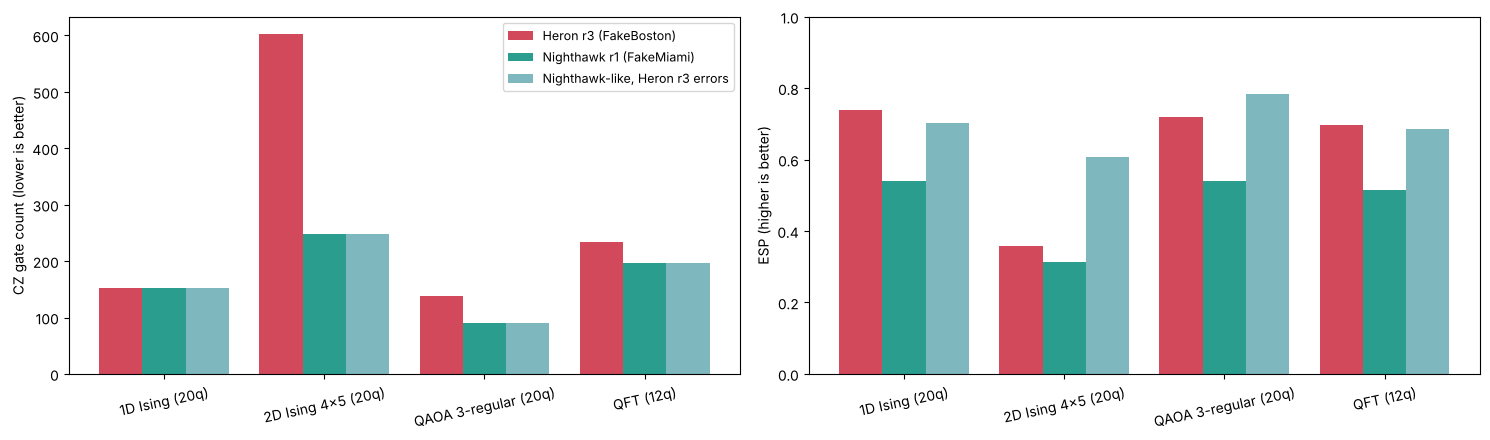

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
colors = {"Heron r3 (FakeBoston)": "#D1495B", "Nighthawk r1 (FakeMiami)": "#2A9D8F",
          "Nighthawk-like, Heron r3 errors": "#7FB7BE"}
circuits = list(BENCH); x = np.arange(len(circuits)); w = 0.27
for i, (bname, c) in enumerate(colors.items()):
    sub = bench[bench.backend == bname].set_index("circuit").loc[circuits]
    axes[0].bar(x + (i - 1) * w, sub["CZ"], w, label=bname, color=c)
    axes[1].bar(x + (i - 1) * w, sub["ESP"], w, label=bname, color=c)
for ax, yl in zip(axes, ["CZ gate count (lower is better)", "ESP (higher is better)"]):
    ax.set_xticks(x); ax.set_xticklabels(circuits, rotation=12); ax.set_ylabel(yl)
axes[1].set_ylim(0, 1); axes[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

**結果の読み方**（数値は作成時の実行結果です。ライブラリのバージョンによって多少変わります）

- **1D Ising：** 3つのバックエンドで CZ 数は同じ（152）です。鎖はどちらの格子にも載るので、差が出るのは誤り率（ESP）だけです。
- **2D Ising：** ヘビーヘックスでは、格子に載らない結合を SWAP で補うので、CZ が約 600 まで増えます。正方格子では 4×5 格子がそのまま埋め込めるので **SWAP がゼロ**になり、CZ は 248（＝結合31本×4ステップ×2）です。2量子ビット深さも約 4 分の 1 になります。
- **QAOA / QFT：** 遠い量子ビット同士の相互作用が多い回路です。正方格子のほうが CZ が 2〜4 割少なく済みます。

**3本目の棒（Nighthawk型＋Heron r3 並みの誤り率）がポイントです。** 格子の効果と誤り率の効果を切り分けると、次のように読めます。

- 青緑（FakeMiami）と赤（FakeBoston）の差 ＝ 格子の効果 ＋ 誤り率の差
- 薄い青（自作）と赤の差 ＝ **ほぼ格子だけの効果**

この FakeMiami のスナップショットは、CZ 誤り率が Boston の約 2.3 倍です。そのため、CZ 数を減らした効果が誤り率の高さで打ち消され、**ESP では 4 つの回路すべてで Boston に負けています**。一方、誤り率をそろえた自作版では、2D Ising の ESP が約 0.36 → 約 0.6 に大きく改善し、QAOA でも Boston を上回ります。

1D Ising で自作版が Boston よりわずかに低いのは、自作版に「特に誤りの少ない量子ビット」がないからです（6章の説明と同じ理由）。

まとめると、「正方格子が有利」というのは**ゲートの品質がそろったときの話**です。実機を選ぶときは、格子の形と、その日の誤り率の両方を見る必要があります。

## 8. 量子化学：LUCJ 回路で格子の違いを見る

IBM と理研の量子化学実験（SQD）で使われている **LUCJ アンザッツ**（local unitary cluster Jastrow）は、格子の形に合わせて「どの相互作用を入れるか」を選ぶ回路です。

- 量子ビットは、α スピン軌道の鎖と β スピン軌道の鎖、2本に並べます。
- **α–α, β–β（同じスピン同士）の相互作用：** 鎖の上の隣同士なので、どちらの格子でも入れられます。
- **α–β（違うスピン同士）の相互作用：** 2本の鎖をつなぐ結合が必要です。
  - ヘビーヘックス：鎖をつなぐ橋が 4 軌道に 1 か所しかないので、`p % 4 == 0` の軌道だけ。
  - 正方格子：2本の鎖を「はしご」のように並べられるので、原理的にすべての軌道で入れられます。

`ffsim` には、この配置を自動で探してくれる `generate_lucj_pass_manager(backend, norb, connectivity, interaction_pairs)` があります。`connectivity="square"` を指定すると、正方格子用の配置を探します。希望した α–β ペアが載りきらないときは、リストの**後ろから**削っていき、実際に採用できたペアのリストを返してくれます。

### 8.1 N₂ / 6-31G（16軌道 → 32量子ビット）：回路コストの比較

まず、実際の量子化学でよく扱う規模で、**トランスパイル後の回路**を比べます。シミュレーションはせず、変換だけ行います。

LUCJ のパラメータは、古典計算の CCSD の振幅から作ります（`from_t_amplitudes`）。実際の SQD 実験でも、この方法がよく使われています。

In [13]:
import pyscf, pyscf.cc, pyscf.mcscf, pyscf.ao2mo
import ffsim

def n2_problem(basis, bond=1.1, n_frozen=2):
    mol = pyscf.gto.Mole()
    mol.build(atom=[["N", (0, 0, 0)], ["N", (bond, 0, 0)]], basis=basis, symmetry="Dooh", verbose=0)
    scf = pyscf.scf.RHF(mol).run()
    frozen = list(range(n_frozen))
    active = [i for i in range(mol.nao_nr()) if i not in frozen]
    norb = len(active)
    nelec = (int(sum(scf.mo_occ[active]) // 2),) * 2
    ccsd = pyscf.cc.CCSD(scf, frozen=frozen).run()
    return dict(mol=mol, scf=scf, active=active, norb=norb, nelec=nelec, ccsd=ccsd)

def lucj_circuit(prob, pairs_aa, pairs_ab):
    op = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
        prob["ccsd"].t2, t1=prob["ccsd"].t1, n_reps=1, interaction_pairs=(pairs_aa, pairs_ab))
    q = QuantumRegister(2 * prob["norb"], "q"); qc = QuantumCircuit(q)
    qc.append(ffsim.qiskit.PrepareHartreeFockJW(prob["norb"], prob["nelec"]), q)
    qc.append(ffsim.qiskit.UCJOpSpinBalancedJW(op), q)
    qc.measure_all()
    return qc

def transpile_lucj(prob, backend, connectivity, requested_ab, seed=1):
    norb = prob["norb"]
    pairs_aa = [(p, p + 1) for p in range(norb - 1)]
    pm, accepted_ab = ffsim.qiskit.generate_lucj_pass_manager(
        backend, norb, connectivity, interaction_pairs=(pairs_aa, requested_ab),
        optimization_level=3, seed_transpiler=seed)
    pm.pre_init = ffsim.qiskit.PRE_INIT     # ffsim のゲートを Qiskit 標準ゲートに展開する前処理
    isa = pm.run(lucj_circuit(prob, pairs_aa, accepted_ab))
    return isa, accepted_ab

big = n2_problem("6-31g")
print("N2/6-31G: 軌道数 =", big["norb"], " 電子数(α,β) =", big["nelec"], " → 量子ビット数 =", 2 * big["norb"])

N2/6-31G: 軌道数 = 16  電子数(α,β) = (5, 5)  → 量子ビット数 = 32


In [14]:
norb = big["norb"]
every4 = [(p, p) for p in range(0, norb, 4)]   # ヘビーヘックス既定：4軌道に1つ
allab  = [(p, p) for p in range(norb)]         # 正方格子で希望：全部

cases = [("Heron r3 (FakeBoston)",           boston,       "heavy-hex", every4),
         ("Nighthawk r1 (FakeMiami)",        miami,        "square",    allab),
         ("Nighthawk-like, Heron r3 errors", nh_heron_err, "square",    allab)]
rows = []; t0 = time.time()
for name, be, conn, req in cases:
    isa, acc = transpile_lucj(big, be, conn, req)
    rows.append({"backend": name, "格子": conn, "採用された α–β ペア数": len(acc),
                 "CZ": isa.count_ops().get("cz", 0),
                 "2q depth": isa.depth(lambda x: x.operation.num_qubits == 2),
                 "ESP": esp(isa, be)})
print(f"time: {time.time() - t0:.1f} s")
lucj_big = pd.DataFrame(rows).set_index("backend"); lucj_big.round(4)

time: 30.7 s


,格子,採用された α–β ペア数,CZ,2q depth,ESP
backend,,,,,
Heron r3 (FakeBoston),heavy-hex,4,716,70,0.2357
Nighthawk r1 (FakeMiami),square,10,702,64,0.1012
"Nighthawk-like, Heron r3 errors",square,12,704,66,0.2524


**読み方**

- **採用された α–β ペア数：** ヘビーヘックスは 4 個、正方格子は 2 桁です。「すべて」（16 個）にならないのは、実機の格子が 12×10 で、16 軌道の「はしご」をまっすぐには置けないからです。`ffsim` は、置けない分を後ろから削っています。
- **CZ 数・深さ：** α–β ペアを 2.5〜3 倍入れているのに、正方格子の回路のコスト（CZ 約 700、深さ 64〜70）は Heron とほぼ同じです。
- つまり Nighthawk では、**同じ回路コストで、電子相関をより多く表せる（表現力の高い）回路**が作れます。これが「量子化学には正方格子が有利」の具体的な中身です。
- **ESP：** ここでも 7 章と同じ構図になります。FakeMiami は誤り率が高いので ESP が低くなります。一方、誤り率をそろえた自作版は、Heron と同等以上の ESP で、より多くの α–β ペアを入れられています。

### 8.2 N₂ / STO-6G（8軌道 → 16量子ビット）：ノイズ付きサンプリング＋SQD

最後に、シミュレータで実際に**ノイズ付きで回して、エネルギーまで計算**します。16 量子ビット程度なら、ノートPCでも 1 機体あたり 1 分ほどで計算できます。

SQD（サンプルベース量子対角化）の流れは次のとおりです。

1. LUCJ 回路を測定して、電子配置（ビット列）をたくさん集めます。
2. ノイズで電子数が合わなくなったビット列は、**configuration recovery** という手法で修正します。
3. 集めた電子配置が張る小さな部分空間でハミルトニアンを対角化して、エネルギーを求めます。

ここでは、2つの指標を見ます。

- **正しい電子数のサンプルの割合：** ノイズの強さの直接的な目安です。理想なら 100% になります。
- **SQD エネルギーと厳密解（FCI）との差 [mHa]：** 化学的精度の目安は約 1.6 mHa です。

In [15]:
from qiskit_addon_sqd.fermion import diagonalize_fermionic_hamiltonian

small = n2_problem("sto-6g")
norb_s, nelec_s = small["norb"], small["nelec"]

cas = pyscf.mcscf.CASCI(small["scf"], norb_s, nelec_s)
mo = cas.sort_mo(small["active"], base=0)
h1, ecore = cas.get_h1cas(mo)
h2 = pyscf.ao2mo.restore(1, cas.get_h2cas(mo), norb_s)
e_fci = cas.kernel(mo)[0]
print(f"N2/STO-6G: 軌道数 {norb_s}, 電子 {nelec_s}, 量子ビット {2 * norb_s}")
print(f"E(HF)   = {small['scf'].e_tot:.6f} Ha")
print(f"E(CCSD) = {small['ccsd'].e_tot:.6f} Ha")
print(f"E(FCI)  = {e_fci:.6f} Ha   ← 正解")

N2/STO-6G: 軌道数 8, 電子 (5, 5), 量子ビット 16
E(HF)   = -108.542471 Ha
E(CCSD) = -108.697526 Ha
E(FCI)  = -108.701562 Ha   ← 正解


In [16]:
SHOTS = 1000   # 増やすと精度は上がりますが、時間もほぼ比例して増えます

def valid_fraction(bit_array, norb, nelec):
    bits = bit_array.get_bitstrings()
    # Qiskit のビット列は右端が q0。q0..q(norb-1) が α、残りが β
    na = np.array([b[norb:].count("1") for b in bits])
    nb = np.array([b[:norb].count("1") for b in bits])
    return float(np.mean((na == nelec[0]) & (nb == nelec[1])))

cases = [("Heron r3 (FakeBoston)",           boston,       "heavy-hex", [(p, p) for p in range(0, norb_s, 4)]),
         ("Nighthawk r1 (FakeMiami)",        miami,        "square",    [(p, p) for p in range(norb_s)]),
         ("Nighthawk-like, Heron r3 errors", nh_heron_err, "square",    [(p, p) for p in range(norb_s)])]
rows = []
for name, be, conn, req in cases:
    t0 = time.time()
    isa, acc = transpile_lucj(small, be, conn, req)
    sim = AerSimulator.from_backend(be, seed_simulator=11)
    bit_array = SamplerV2(mode=sim).run([isa], shots=SHOTS).result()[0].data.meas
    sqd = diagonalize_fermionic_hamiltonian(h1, h2, bit_array, samples_per_batch=300, norb=norb_s,
                                            nelec=nelec_s, num_batches=3, max_iterations=5, seed=11)
    e = sqd.energy + ecore
    rows.append({"backend": name, "α–β ペア": len(acc), "CZ": isa.count_ops().get("cz", 0),
                 "正しい電子数の割合": valid_fraction(bit_array, norb_s, nelec_s),
                 "E(SQD) [Ha]": e, "誤差 vs FCI [mHa]": (e - e_fci) * 1000,
                 "時間 [s]": time.time() - t0})
sqd_df = pd.DataFrame(rows).set_index("backend"); sqd_df.round(4)

,α–β ペア,CZ,正しい電子数の割合,E(SQD) [Ha],誤差 vs FCI [mHa],時間 [s]
backend,,,,,,
Heron r3 (FakeBoston),2,172,0.729,-108.6965,5.0133,96.4988
Nighthawk r1 (FakeMiami),8,176,0.494,-108.6934,8.1291,58.0952
"Nighthawk-like, Heron r3 errors",8,176,0.716,-108.6948,6.7886,51.1619


**読み方と注意点**

- **正しい電子数の割合：** 回路の CZ 数と誤り率で決まります。作成時の実行では、Boston が約 73%、誤り率をそろえた自作版が約 72%、FakeMiami が約 49% でした。自作版は α–β ペアを 4 倍入れても（CZ は 172 → 176 とほぼ同じ）、Heron と同じくらいの割合を保っています。FakeMiami は CZ と読み出しの誤り率が高いので、割合が下がっています。
- **SQD エネルギー：** 3 つとも、厳密解（FCI）との差は数 mHa〜十数 mHa です（作成時の複数回の実行で、3〜16 mHa の範囲でばらつきました）。バックエンドの間の差は、ショット数や乱数による揺らぎと同じくらいの大きさです。この小さい問題では、CCSD の振幅から作った LUCJ でもともと良い電子配置が出やすく、configuration recovery もよく効くので、格子の差がエネルギーに出にくいのです。精度を上げたいときは `SHOTS` と `samples_per_batch` を増やしてください。
- 格子の差がエネルギーにはっきり出るのは、**部分空間を全部は集めきれない大きな分子**です。研究で比べるときは、8.1 節のような規模で「同じ CZ 予算でどれだけ表現力を入れられるか」を見るのが本質的です。
- ショット数や乱数シードで結果は揺らぎます。結論を出すときは、何回か繰り返して平均と標準偏差を取ってください。

## 9. Nighthawk r2（ibm_phoenix）を再現する

2026年9月に登場した **Nighthawk r2**（ibm_phoenix）には、まだ公式のフェイクバックエンドがありません。そこで、IBM Quantum Platform の機体一覧に公開されている数値から、r2 をシミュレータ上に組み立てます。

**公開値（2026年10月、IBM Quantum Platform の機体一覧より）**

| | Nighthawk r1（ibm_miami） | **Nighthawk r2（ibm_phoenix）** | Heron r3（ibm_boston） |
|---|---|---|---|
| 量子ビット数 | 120 | 120 | 156 |
| 物理量子ビット数 | 338 | **458** | 332 |
| 2量子ビット誤り（最良） | 1.045×10⁻³ | **7.244×10⁻⁴** | 5.193×10⁻⁴ |
| 2量子ビット誤り（層状） | 8.881×10⁻³ | **3.499×10⁻³** | 2.410×10⁻³ |
| 読み出し誤り（中央値） | 2.026×10⁻² | **7.202×10⁻³** | 3.540×10⁻³ |

- 「物理量子ビット数」は、r1 では 120（量子ビット）＋218（カプラー）＝338、Heron r3 では 156＋176＝332 で、ぴったり合います。r2 はそこから**ちょうど 120 増えている**ので、量子ビット1つにつき1個ずつ高速リセット用の素子が増えたと考えられます。つまり、**格子（12×10、カプラー218本）は r1 と同じ**と仮定します。これは公表されている数値からの推測で、IBM の公式な説明ではありません。
- 「層状（layered）」の誤り率は、多数の CZ を同時に並べて動かしたときの1ゲートあたりの誤り率です。クロストークなどの影響が入るので、1個ずつ測った誤り率（フェイクバックエンドの CZ 誤り率はこちら）より大きくなります。

**2通りの作り方**

| | 方法1：FakeMiami を縮める | 方法2：公開値を一様に入れる |
|---|---|---|
| 作り方 | FakeMiami の量子ビットごとの誤り率に、r1→r2 の改善比を掛ける | 6章の `make_nighthawk_like()` に、r2 の公開値をそのまま入れる |
| CZ 誤り率 | ×（3.499/8.881）≈ ×0.39 | 一律 3.5×10⁻³（層状の値） |
| 読み出し誤り率 | ×（7.202/20.26）≈ ×0.36 | 一律 0.72% |
| 性格 | 実機らしい**ばらつきが残る**。現実的な見積もり | ばらつきなし。層状の値を使うので**かなり控えめ（悲観的）な見積もり** |

1量子ビットゲートの誤り率と T1/T2 は公開値がないので、どちらの方法も r1（FakeMiami）の値のままにしています。

**再現できないこと：** 高速リセットは主に**速さ**の改善です（1秒あたりの回路数が r1 の約 250 から約 11 万に増えました）。Aer は計算の結果を再現するもので、実機の実行時間は再現しないので、この効果はシミュレーションには出ません。

In [17]:
PUBLIC = {   # IBM Quantum Platform の機体一覧（2026年10月時点）
    "ibm_miami (r1)":   {"2q_best": 1.045e-3, "2q_layered": 8.881e-3, "readout": 2.026e-2},
    "ibm_phoenix (r2)": {"2q_best": 7.244e-4, "2q_layered": 3.499e-3, "readout": 7.202e-3},
    "ibm_boston (Heron r3)": {"2q_best": 5.193e-4, "2q_layered": 2.410e-3, "readout": 3.540e-3},
}
R1, R2 = PUBLIC["ibm_miami (r1)"], PUBLIC["ibm_phoenix (r2)"]
SCALE = {"cz": R2["2q_layered"] / R1["2q_layered"], "measure": R2["readout"] / R1["readout"]}
print("r1 → r2 の改善比:", {k: round(v, 3) for k, v in SCALE.items()})


def scale_backend(src, scale, name):
    # src の Target を1命令ずつコピーし、scale に書かれた命令だけ誤り率を何倍かにする
    t = src.target
    new_t = Target(num_qubits=t.num_qubits, dt=t.dt,
                   qubit_properties=[src.qubit_properties(q) for q in range(t.num_qubits)])
    for op_name in t.operation_names:
        op = t.operation_from_name(op_name)
        if isinstance(op, type):          # if_else などの制御フロー命令（全量子ビット共通・誤り率なし）
            new_t.add_instruction(op, name=op_name)
            continue
        props = {}
        for qargs, p in t[op_name].items():
            if p is None:
                props[qargs] = None
                continue
            err = p.error
            if err is not None and op_name in scale:
                err = min(err * scale[op_name], 1.0)
            props[qargs] = InstructionProperties(duration=p.duration, error=err)
        new_t.add_instruction(op, props, name=op_name)
    return NighthawkLike(new_t, name=name)


# 方法1：FakeMiami の誤り率を r2 並みに縮める（ばらつきは残る）
r2_scaled = scale_backend(miami, SCALE, name="Nighthawk r2 (method 1: scaled FakeMiami)")

# 方法2：公開値（層状の誤り率）を一様に入れる（控えめな見積もり）
r2_uniform = make_nighthawk_like(name="Nighthawk r2 (method 2: uniform public values)",
                                 cz_error=R2["2q_layered"], readout_error=R2["readout"])

pd.DataFrame({"FakeMiami (r1)": summarize(miami),
              "r2 方法1": summarize(r2_scaled),
              "r2 方法2": summarize(r2_uniform),
              "FakeBoston (Heron r3)": summarize(boston)}).loc[
    ["量子ビット数", "カプラー数（結合の本数）", "CZ誤り率（中央値）", "読み出し誤り率（中央値）", "T1 中央値 [µs]"]]

r1 → r2 の改善比: {'cz': 0.394, 'measure': 0.355}


,FakeMiami (r1),r2 方法1,r2 方法2,FakeBoston (Heron r3)
量子ビット数,120,120,120,156
カプラー数（結合の本数）,218,218,218,176
CZ誤り率（中央値）,0.002978,0.001173,0.003499,0.001275
読み出し誤り率（中央値）,0.017883,0.006357,0.007202,0.005127
T1 中央値 [µs],330.217672,330.217672,330.217672,292.435651


方法1では、CZ 誤り率の中央値が FakeBoston（Heron r3）と**ほぼ同じ水準**まで下がります。方法2は、層状の値を使っているので CZ 誤り率が大きめです。

**現実の r2 は、おそらく方法1と方法2の間にある**と考えてください。以下では、両方で比較します。

### 9.1 GHZ 状態（一直線の回路）

まずは5章と同じ GHZ で、r2 の素性を確認します。

In [18]:
rows = []
for n in [4, 8, 12, 16]:
    for be in [r2_scaled, r2_uniform]:
        isa = transpile(ghz(n), be, optimization_level=3, seed_transpiler=1)
        rows.append({"n": n, "backend": be.name, "GHZ成功率": ghz_success(run_counts(isa, be), n)})
pd.concat([ghz_df[["n", "backend", "GHZ成功率"]], pd.DataFrame(rows)]) \
  .pivot(index="n", columns="backend", values="GHZ成功率").round(3)

backend,FakeBoston (Heron r3),FakeMiami (Nighthawk r1),Nighthawk r2 (method 1: scaled FakeMiami),Nighthawk r2 (method 2: uniform public values)
n,,,,
4,0.988,0.958,0.986,0.962
8,0.962,0.890,0.958,0.918
12,0.948,0.848,0.941,0.880
16,0.923,0.774,0.908,0.824


GHZ は一直線の回路なので、格子の差は出ず、**誤り率の差だけ**が結果に出ます（5章を参照）。

- **方法1：** 16量子ビットで約 0.91 です。r1（FakeMiami）の約 0.77 から大きく改善し、Heron r3（約 0.92）とほぼ並びました。
- **方法2：** 約 0.82 です。r1 よりは良いものの、Heron r3 には届きません。ただしこれは、層状の誤り率（並列実行時の値）を使った控えめな見積もりだからです。

### 9.2 7章の比較をやり直す：Heron r3 / r1 / r2

7章と同じ4種類の回路を、4つのバックエンドで比べます。

In [19]:
BACKENDS_R2 = {"Heron r3 (FakeBoston)": boston,
               "Nighthawk r1 (FakeMiami)": miami,
               "Nighthawk r2 (method 1)": r2_scaled,
               "Nighthawk r2 (method 2)": r2_uniform}
rows = []; t0 = time.time()
for cname, qc in BENCH.items():
    for bname, be in BACKENDS_R2.items():
        isa = best_transpile(qc, be)
        rows.append({"circuit": cname, "backend": bname, "CZ": isa.count_ops().get("cz", 0),
                     "2q depth": isa.depth(lambda x: x.operation.num_qubits == 2), "ESP": esp(isa, be)})
bench_r2 = pd.DataFrame(rows)
print(f"transpile time: {time.time() - t0:.1f} s")
bench_r2.pivot(index="circuit", columns="backend", values="ESP").round(3)

transpile time: 5.8 s


backend,Heron r3 (FakeBoston),Nighthawk r1 (FakeMiami),Nighthawk r2 (method 1),Nighthawk r2 (method 2)
circuit,,,,
1D Ising (20q),0.738,0.541,0.767,0.471
2D Ising 4x5 (20q),0.359,0.314,0.602,0.326
QAOA 3-regular (20q),0.721,0.541,0.777,0.607
QFT (12q),0.697,0.514,0.736,0.422


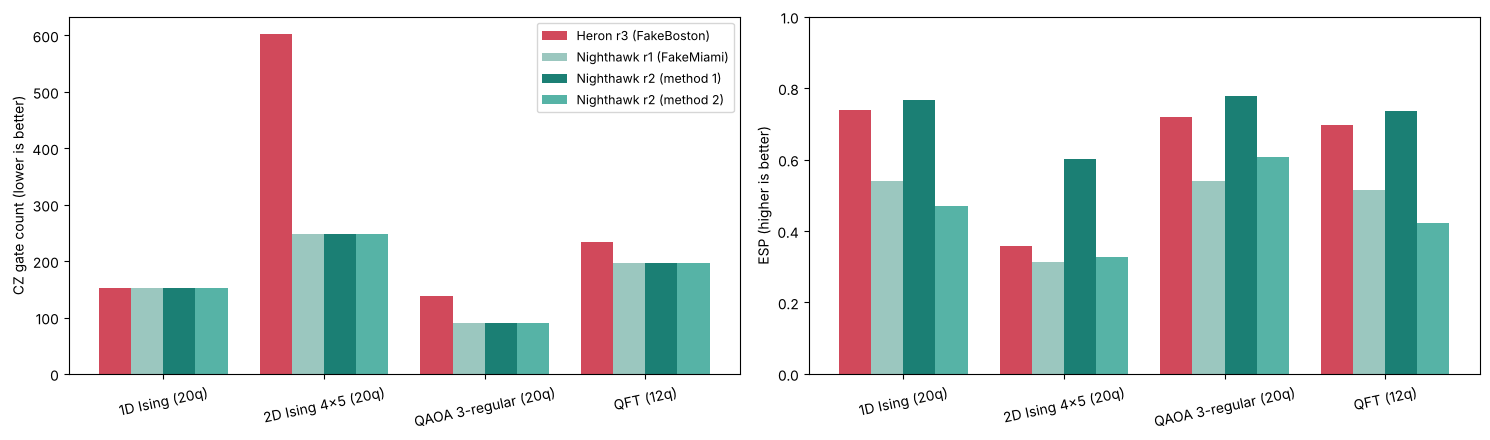

backend,Nighthawk r1 (FakeMiami) / Heron,Nighthawk r2 (method 1) / Heron,Nighthawk r2 (method 2) / Heron
circuit,,,
1D Ising (20q),0.73,1.04,0.64
2D Ising 4x5 (20q),0.87,1.68,0.91
QAOA 3-regular (20q),0.75,1.08,0.84
QFT (12q),0.74,1.06,0.61


In [20]:
colors_r2 = {"Heron r3 (FakeBoston)": "#D1495B", "Nighthawk r1 (FakeMiami)": "#9BC7BF",
             "Nighthawk r2 (method 1)": "#1B7F74", "Nighthawk r2 (method 2)": "#56B3A6"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(circuits)); w = 0.2
for i, (bname, c) in enumerate(colors_r2.items()):
    sub = bench_r2[bench_r2.backend == bname].set_index("circuit").loc[circuits]
    axes[0].bar(x + (i - 1.5) * w, sub["CZ"], w, label=bname, color=c)
    axes[1].bar(x + (i - 1.5) * w, sub["ESP"], w, label=bname, color=c)
for ax, yl in zip(axes, ["CZ gate count (lower is better)", "ESP (higher is better)"]):
    ax.set_xticks(x); ax.set_xticklabels(circuits, rotation=12); ax.set_ylabel(yl)
axes[1].set_ylim(0, 1); axes[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

# Heron r3 に対する ESP の比（1より大きければ r2 の勝ち）
esp_tab = bench_r2.pivot(index="circuit", columns="backend", values="ESP")
(esp_tab.div(esp_tab["Heron r3 (FakeBoston)"], axis=0)
        .drop(columns="Heron r3 (FakeBoston)").round(2)
        .rename(columns=lambda c: c + " / Heron"))

**方法1では、4つの回路すべてで ESP が Heron r3 を上回り、r1 で負けていた結果が逆転しました。**

| 回路 | r1 / Heron | **r2 方法1 / Heron** |
|---|---|---|
| 1D Ising | 約 0.73 | 約 1.04 |
| **2D Ising** | 約 0.87 | **約 1.68** |
| QAOA | 約 0.75 | 約 1.08 |
| QFT | 約 0.74 | 約 1.06 |

- **2D Ising** で差が一番大きくなります（Heron の約 1.7 倍）。CZ 数が 603 → 248 に減る効果が、ゲートの品質が追いついたことで、そのまま成功確率に出ています。
- 格子の差が出ない **1D Ising** でもわずかに勝っているのは、方法1の CZ 誤り率の中央値（約 1.17×10⁻³）が、FakeBoston（約 1.28×10⁻³）より少しだけ低いからです。

**方法2は4つとも負けています（約 0.6〜0.9）が、これは比べ方が公平でないためです。** 方法2の r2 には「層状（並列実行時）」の誤り率を入れていますが、FakeBoston に入っているのは「1個ずつ測った」誤り率です。層状の値は、1個ずつの値より大きく出ます。そこで次のセルで、Heron r3 にも層状の公開値（2.41×10⁻³）を入れて、**層状どうしで比べ直します**。

In [21]:
# 公平な比較：Heron r3 も「層状」の公開値に合わせる（FakeBoston の誤り率を、中央値が公開値になるように拡大）
H = PUBLIC["ibm_boston (Heron r3)"]
boston_layered = scale_backend(
    boston,
    {"cz": H["2q_layered"] / median_error(boston, "cz"), "measure": H["readout"] / median_error(boston, "measure")},
    name="Heron r3 (layered public values)")
print("Heron r3（層状）の CZ 誤り率の中央値:", round(median_error(boston_layered, "cz"), 5),
      " / r2 方法2:", R2["2q_layered"])

rows = []
for cname, qc in BENCH.items():
    for bname, be in [("Heron r3 (layered)", boston_layered), ("Nighthawk r2 (method 2)", r2_uniform)]:
        isa = best_transpile(qc, be)
        rows.append({"circuit": cname, "backend": bname, "ESP": esp(isa, be)})
fair = pd.DataFrame(rows).pivot(index="circuit", columns="backend", values="ESP")
fair["r2 / Heron"] = fair["Nighthawk r2 (method 2)"] / fair["Heron r3 (layered)"]
fair.round(3)

Heron r3（層状）の CZ 誤り率の中央値: 0.00241  / r2 方法2: 0.003499


backend,Heron r3 (layered),Nighthawk r2 (method 2),r2 / Heron
circuit,,,
1D Ising (20q),0.650,0.471,0.726
2D Ising 4x5 (20q),0.200,0.326,1.630
QAOA 3-regular (20q),0.646,0.607,0.939
QFT (12q),0.565,0.422,0.747


層状の公開値どうし（Heron r3：2.41×10⁻³、r2：3.50×10⁻³）で比べると、次のようになりました。

| 回路 | r2 方法2 / Heron r3（層状） | 判定 |
|---|---|---|
| **2D Ising** | **約 1.63** | **r2 の勝ち** |
| QAOA | 約 0.94 | ほぼ互角 |
| 1D Ising | 約 0.73 | Heron r3 の勝ち |
| QFT | 約 0.75 | Heron r3 の勝ち |

層状の値で見ると、r2 の1ゲートあたりの誤り率は、まだ Heron r3 の約 1.45 倍あります。それでも **2D Ising では、CZ を約 6 割減らせる効果が誤り率の差を上回り、r2 が勝ちます**。一方、CZ の削減が小さい回路（1D Ising は削減ゼロ、QFT は約 16% 減）では、誤り率の差がそのまま出て負けます。

**9.2 節のまとめ**

- 「1個ずつ測った誤り率」で見積もる方法1では、r2 は**4つの回路すべてで Heron r3 を逆転**します。
- 「層状の誤り率」で見積もる控えめな方法2でも、**格子が効く 2次元的な回路では r2 が勝ち**ます。
- 実際の r2 は、この2つの間にあると考えられます。どちらの見積もりでも、「格子に合った問題なら r2 は Heron r3 に勝てる」という結論は変わりません。

### 9.3 8章の比較をやり直す：量子化学（LUCJ）

**(a) N₂ / 6-31G（32量子ビット）の回路コストと ESP**

In [22]:
rows = []; t0 = time.time()
for name, be in [("Nighthawk r2 (method 1)", r2_scaled), ("Nighthawk r2 (method 2)", r2_uniform)]:
    isa, acc = transpile_lucj(big, be, "square", allab)
    rows.append({"backend": name, "格子": "square", "採用された α–β ペア数": len(acc),
                 "CZ": isa.count_ops().get("cz", 0),
                 "2q depth": isa.depth(lambda x: x.operation.num_qubits == 2), "ESP": esp(isa, be)})
print(f"time: {time.time() - t0:.1f} s")
lucj_r2 = pd.concat([lucj_big.drop(index="Nighthawk-like, Heron r3 errors"),
                     pd.DataFrame(rows).set_index("backend")])
lucj_r2.round(4)

time: 34.4 s


,格子,採用された α–β ペア数,CZ,2q depth,ESP
backend,,,,,
Heron r3 (FakeBoston),heavy-hex,4,716,70,0.2357
Nighthawk r1 (FakeMiami),square,10,702,64,0.1012
Nighthawk r2 (method 1),square,12,704,66,0.2841
Nighthawk r2 (method 2),square,12,704,66,0.0438


- **方法1：** α–β ペアを Heron の3倍（4 → 12）入れたうえで、ESP も Heron r3 を上回りました（約 0.24 → 約 0.28）。r1 では、表現力は上がっても ESP が半分以下（約 0.10）でした。r2 の品質なら、**表現力と成功確率の両方で Heron r3 に勝てる**ということです。
- **方法2：** ESP は約 0.04 と低く出ます。700 個近い CZ すべてに層状の誤り率（3.5×10⁻³）を一律にかけているので、非常に悲観的な見積もりになっています。


**(b) N₂ / STO-6G（16量子ビット）のノイズ付きサンプリング＋SQD**

8.2 節と同じ条件（ショット数・乱数シード）で、r2 の2通りを追加で実行します。1つあたり 1 分ほどかかります。

In [23]:
rows = []
for name, be in [("Nighthawk r2 (method 1)", r2_scaled), ("Nighthawk r2 (method 2)", r2_uniform)]:
    t0 = time.time()
    isa, acc = transpile_lucj(small, be, "square", [(p, p) for p in range(norb_s)])
    sim = AerSimulator.from_backend(be, seed_simulator=11)
    bit_array = SamplerV2(mode=sim).run([isa], shots=SHOTS).result()[0].data.meas
    sqd = diagonalize_fermionic_hamiltonian(h1, h2, bit_array, samples_per_batch=300, norb=norb_s,
                                            nelec=nelec_s, num_batches=3, max_iterations=5, seed=11)
    e = sqd.energy + ecore
    rows.append({"backend": name, "α–β ペア": len(acc), "CZ": isa.count_ops().get("cz", 0),
                 "正しい電子数の割合": valid_fraction(bit_array, norb_s, nelec_s),
                 "E(SQD) [Ha]": e, "誤差 vs FCI [mHa]": (e - e_fci) * 1000, "時間 [s]": time.time() - t0})
sqd_r2 = pd.concat([sqd_df.drop(index="Nighthawk-like, Heron r3 errors"), pd.DataFrame(rows).set_index("backend")])
sqd_r2.round(4)

,α–β ペア,CZ,正しい電子数の割合,E(SQD) [Ha],誤差 vs FCI [mHa],時間 [s]
backend,,,,,,
Heron r3 (FakeBoston),2,172,0.729,-108.6965,5.0133,96.4988
Nighthawk r1 (FakeMiami),8,176,0.494,-108.6934,8.1291,58.0952
Nighthawk r2 (method 1),8,176,0.696,-108.6922,9.3145,56.2026
Nighthawk r2 (method 2),8,176,0.490,-108.6987,2.8529,61.0572


- **正しい電子数の割合：** 方法1は約 70% で、r1（約 49%）から大きく改善し、Heron r3（約 73%）とほぼ同じです。しかも、α–β ペアを Heron の4倍入れた回路でこの値です。方法2は約 48% で、r1 と同程度でした。
- **SQD エネルギー：** 8.2 節と同じく、どのバックエンドでも厳密解との差は数 mHa〜十数 mHa の範囲でばらつき、実行ごとの揺らぎのほうが大きく出ます。この小さな問題では、エネルギーでの優劣は判断できません。大きな分子で比べるのが次の課題です。

## 10. まとめと次のステップ

**このノートブックで再現できたこと**

1. `FakeMiami` で、Nighthawk r1 の**正方格子（次数4）**と、実機スナップショットのノイズを再現しました。
2. 誤り率を自由に設定できる **Nighthawk 型バックエンド**（`make_nighthawk_like`）を作り、格子の効果と誤り率の効果を切り分けられるようにしました。
3. Heron r3（`FakeBoston`）との比較では、次のことが分かりました。
   - 鎖状の回路では差がない
   - 2D 格子・QAOA・QFT のように**鎖に収まらない回路では、正方格子のほうが CZ 数が少ない**
   - ただし、実際の性能（ESP）は 1 ゲートあたりの誤り率にも大きく左右される
4. 量子化学の LUCJ 回路では、正方格子のほうが**同じ回路コストで α–β 相互作用を何倍も多く入れられる**ことを確認しました。
5. **Nighthawk r2 の再現（9章）：** 公開値から r2 を2通りの方法で組み立てました。
   - 方法1（FakeMiami の誤り率を r2 並みに縮めたもの）では、**r1 で負けていた ESP が、7章の4つの回路すべてで Heron r3 を逆転**しました。2D Ising では約 1.7 倍です。
   - 量子化学の LUCJ でも、α–β ペアを3倍入れたうえで ESP が Heron r3 を上回りました。
   - 層状の公開値どうしで比べる控えめな見積もり（方法2）でも、2次元的な回路では r2 が有利です（9.2 節）。

**次に試すと面白いこと**

- 9章の `SCALE` を変えて、**r3 以降の性能を仮定**して比べる。
- アクセス権があれば、`AerSimulator.from_backend(QiskitRuntimeService().backend("ibm_phoenix"))` で、**実機 r2 のその日の校正データ**を使って9章をやり直す。
- 8.1 節の分子を変える（H₂O、ベンゼンの π 軌道、Fe–S クラスターのモデルなど）。
- `n_reps=2` にして、LUCJ を 2 層にしたときのコストを比べる。
- 実機で試すときは、`QiskitRuntimeService().backend("ibm_miami")` を `SamplerV2(mode=...)` に渡すだけで、同じコードが動きます。ただし、Nighthawk 機の利用には対応するプランが必要です。